In [1]:
# ─────────────────────────────────────────────────────────────────────
# NOTEBOOK 05b · CELL 1 · SETUP: WIN PROBABILITY, THE BUILDING BLOCK OF "PRESSURE"
# Purpose: measure, ball by ball, how likely the batting side is to win. Pressure will then be defined as "how much the NEXT ball
#          can move that probability". A ball that can swing the match is a pressure ball; a ball in a dead game is not.
# ─────────────────────────────────────────────────────────────────────
import warnings, time
import numpy as np
import pandas as pd
import lightgbm as lgb
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import GroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 80); pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
OUT_DIR = Path("interim"); SEED = 42; rng = np.random.default_rng(SEED)

def load_table(name):
    return pd.read_parquet(OUT_DIR / f"{name}.parquet") if (OUT_DIR / f"{name}.parquet").exists() else pd.read_pickle(OUT_DIR / f"{name}.pkl")
def save_table(df, name):
    try:
        df.to_parquet(OUT_DIR / f"{name}.parquet", index=False); return "parquet"
    except Exception:
        df.to_pickle(OUT_DIR / f"{name}.pkl"); return "pickle"

ball    = load_table("ball_master")
matches = load_table("matches_clean")
players = load_table("players")
# safe to re-run: drop columns this notebook creates
new_cols = ["wp_before", "wp_after", "dwp", "li_raw", "li", "li_band", "press_main", "press_top15", "press_top20", "press_top25", "press_top30", "bat_press", "bowl_press",
            "bat_press15", "bat_press20", "bat_press25", "bat_press30", "bowl_press15", "bowl_press20", "bowl_press25", "bowl_press30", "rule_press"]
ball = ball.drop(columns=[c for c in new_cols if c in ball.columns])

# 1a) The data must be in playing order inside each innings: the "next ball" is the next row.
g = ball.groupby(["match_id", "innings"]).innings_ball_num
assert (g.diff().dropna() > 0).all(), "balls are not in playing order"
print(f"ball_master: {len(ball):,} balls, in playing order inside every innings (check passed).")

# 1b) THE TARGET: did the batting side go on to win this match?  (1 = yes, 0 = no)
# Only matches with a clean, decided result are used to LEARN win probability: both innings played, no rain revision (the target
# and the overs change mid-game), and no super over (the winner of a tied match is decided by something other than the innings).
mm = matches.set_index("match_id")
res = mm.result.fillna("")
clean = (mm.complete_match & ~mm.is_revised & mm.win_team_id.notna() & (mm.n_innings == 2)
         & ~res.str.contains("uper|ied", case=False, regex=True))
ball["bat_won"] = (ball.match_id.map(mm.win_team_id) == ball.batting_team_id).astype(float).where(ball.match_id.map(mm.win_team_id).notna())
ball["clean_match"] = ball.match_id.map(clean).fillna(False).astype(bool)
print(f"Matches used to learn win probability: {int(clean.sum())} of {len(mm)}  (the rest still get a win probability from the model, but never teach it).")
print(f"Batting side wins {ball.loc[ball.clean_match, 'bat_won'].mean():.1%} of balls (should be ~50%: every ball is seen from the batting side).")

# 1c) THE INPUTS come in cell 2. The rule is the same as notebook 04: only the state of the game before the ball, and no player
# identity. Two models, one per innings, because the question is different: in the chase the target is known ("27 off 12"), while
# in the first innings the model must judge how good the score is for this ground (score_vs_par from notebook 03) and how
# strong the sides are (Elo gap from notebook 02).
for c in ["bat_is_home", "impact_era"]:
    ball[c] = ball[c].astype(int)
print("Rows by innings:", ball.innings.value_counts().sort_index().to_dict())

C:\Users\User\anaconda3\lib\site-packages\dask\dataframe\utils.py:367: FutureWarning: pandas.Int64Index is deprecated and will be removed from pandas in a future version. Use pandas.Index with the appropriate dtype instead.
  _numeric_index_types = (pd.Int64Index, pd.Float64Index, pd.UInt64Index)
C:\Users\User\anaconda3\lib\site-packages\dask\dataframe\utils.py:367: FutureWarning: pandas.Float64Index is deprecated and will be removed from pandas in a future version. Use pandas.Index with the appropriate dtype instead.
  _numeric_index_types = (pd.Int64Index, pd.Float64Index, pd.UInt64Index)
C:\Users\User\anaconda3\lib\site-packages\dask\dataframe\utils.py:367: FutureWarning: pandas.UInt64Index is deprecated and will be removed from pandas in a future version. Use pandas.Index with the appropriate dtype instead.
  _numeric_index_types = (pd.Int64Index, pd.Float64Index, pd.UInt64Index)


ball_master: 200,961 balls, in playing order inside every innings (check passed).
Matches used to learn win probability: 749 of 883  (the rest still get a win probability from the model, but never teach it).
Batting side wins 49.0% of balls (should be ~50%: every ball is seen from the batting side).
Rows by innings: {1: 105727, 2: 95234}


**Procedure**
1. Loaded the ball-by-ball master table, the match table and the player table. Columns this notebook creates are dropped first, so the cell can be re-run safely.
2. Checked that balls sit in playing order inside every innings, because "the next ball" is simply the next row.
3. Defined the target: `bat_won` is 1 if the batting side went on to win the match. Flagged "clean" matches (both innings played, no rain revision, no tie or super over, winner known). Only clean matches teach the win-probability model.

**Observations**
- 200,961 balls (105,727 in innings 1 and 95,234 in innings 2). Innings 2 has about 10% fewer balls because chases end as soon as the target is reached. The playing-order check passed.
- 749 of 883 matches (85%) are clean and teach the model. The other 134 still receive a win probability but never train it.
- The batting side wins 49.0% of balls, close to the 50% expected when every ball is seen from the batting side.

In [2]:
# ─────────────────────────────────────────────────────────────────────
# CELL 2 · THE WIN-PROBABILITY MODELS: choosing a model that does not memorise matches
# ─────────────────────────────────────────────────────────────────────
# Same fairness rule as notebook 04: every ball's win probability comes from a model that never saw that ball's MATCH (grouped,
# out-of-fold). FUNCTIONAL reason: pressure will compare the win probability before and after a ball; if the model had memorised
# the match, that jump would be fake.

# 2a) HAND-BUILT INPUTS (FEATURE ENGINEERING = turning raw numbers into the quantities a cricketer reasons with).
# THE KEY IDEA for a chase: "runs needed" means little on its own. What matters is runs needed COMPARED WITH what this situation
# typically yields. 60 needed off 36 balls is easy with 8 wickets in hand and hard with 3. So we first learn, from innings 1,
#   E_rem = the typical number of runs still to come, given balls left, wickets lost and this ground-and-era's scoring level
# (a "resources" idea, in the spirit of Duckworth-Lewis, learned from our own data). Then
#   z = (runs needed - E_rem) / spread,   where the spread of what can still happen grows with the square root of balls left
# (about 2.8 x sqrt(balls left): ~34 runs at the start of an innings, ~6 runs with 6 balls left, checked in the printout below).
# z = 0 means "the target is exactly what a typical innings from here would produce" (a coin flip); positive z = behind.
# TECHNICAL: E_rem is itself learned out-of-fold (same grouped folds) so that no match helps build the expectation used on itself.
N_FOLDS = 5
groups = ball.match_id.to_numpy()
folds = list(GroupKFold(n_splits=N_FOLDS).split(ball, groups=groups))
tot1 = ball[ball.innings == 1].groupby("match_id").total_runs.sum()
ok_rem = ((ball.innings == 1) & ball.match_id.map(~mm.is_revised).fillna(False)).to_numpy()          # innings-1 balls of non-revised matches
ball["rem_actual"] = ball.match_id.map(tot1) - ball.score_before                                       # runs the innings actually added from here
REM_F = ["balls_left", "wkts_before", "venue_par"]
ball["e_rem"] = np.nan
for tr, te in folds:
    tr = tr[ok_rem[tr]]
    mdl = lgb.train(dict(objective="regression", learning_rate=0.05, num_leaves=15, min_child_samples=400, reg_lambda=10, n_jobs=-1,
                         random_state=SEED, verbosity=-1, monotone_constraints=[1, -1, 1]),            # more balls -> more runs; more wickets lost -> fewer; higher-scoring ground -> more
                    lgb.Dataset(ball.iloc[tr][REM_F], ball.rem_actual.iloc[tr]), 300)
    ball.iloc[te, ball.columns.get_loc("e_rem")] = mdl.predict(ball.iloc[te][REM_F])
resid = (ball.rem_actual - ball.e_rem)[ok_rem]
chk = pd.DataFrame({"balls_left": ball.balls_left[ok_rem], "resid": resid}).assign(bucket=lambda d: pd.cut(d.balls_left, [0, 6, 18, 36, 60, 90, 121]))
chk = chk.groupby("bucket").agg(avg_miss=("resid", "mean"), spread=("resid", "std"), mean_balls=("balls_left", "mean"))
chk["spread / sqrt(balls left)"] = chk.spread / np.sqrt(chk.mean_balls)
print("How well does E_rem predict the runs still to come (innings 1)? avg_miss near 0 = unbiased; spread grows with balls left:")
display(chk.round(2))
SPREAD = 2.8
ball["z"]    = (ball.runs_needed - ball.e_rem) / (SPREAD * np.sqrt(ball.balls_left + 3))
ball["z_sq"] = ball.z ** 2
ball["z_bl"] = ball.z * ball.balls_left / 120
ball["z_wk"] = ball.z * ball.wkts_before / 10
# First innings: the gap to par matters more late in the innings and when wickets are in hand.
ball["wk_bl"]  = ball.wkts_before * ball.balls_left / 120
ball["svp_bl"] = ball.score_vs_par * (120 - ball.balls_left) / 120
ball["svp_wk"] = ball.score_vs_par * ball.wkts_before
# crr_s : the current run rate, SMOOTHED. After one ball the raw run rate can read 24 or 0 an over; we blend in 12 balls' worth of an
# average 8-an-over start so the rate settles as real balls arrive (a standard "shrink early noise toward a prior" device).
ball["crr_s"] = 6 * (ball.score_before + 16) / (ball.legal_before + 12)
FEATS = {1: ["score_vs_par", "wkts_before", "balls_left", "elo_diff", "svp_bl", "svp_wk", "wk_bl"],
         2: ["z", "z_sq", "z_bl", "z_wk", "elo_diff", "balls_left", "wkts_before"]}

# 2b) MODEL CHOICE, shown honestly. We first tried a flexible tree model (LightGBM, as in notebook 04) and a plain logistic
# regression. WHY the simple model can win here: we only have ~750 matches, and balls inside one match are not independent
# (a collapse colours the next 30 balls), so a flexible model learns match-specific stories. A logistic regression is smooth, cannot
# do that, and also behaves sensibly in rare situations (e.g. 60 needed off 6 balls).
def cv_logit(innings, feats):
    r = ((ball.innings == innings) & ball.clean_match).to_numpy(); allr = (ball.innings == innings).to_numpy()
    X = ball[feats].fillna(0); y = ball.bat_won
    oof = pd.Series(np.nan, index=ball.index)
    for tr, te in folds:
        tr = tr[r[tr]]; te = te[allr[te]]
        mu, sd = X.iloc[tr].mean(), X.iloc[tr].std().replace(0, 1)
        lr = LogisticRegression(max_iter=3000).fit((X.iloc[tr] - mu) / sd, y.iloc[tr])
        oof.iloc[te] = lr.predict_proba((X.iloc[te] - mu) / sd)[:, 1]
    return oof

def cv_lgb(innings, feats, mono):
    r = ((ball.innings == innings) & ball.clean_match).to_numpy(); allr = (ball.innings == innings).to_numpy()
    X = ball[feats]; y = ball.bat_won; oof = pd.Series(np.nan, index=ball.index)
    P = dict(objective="binary", learning_rate=0.03, num_leaves=7, min_child_samples=1500, subsample=0.8, subsample_freq=1, reg_lambda=30,
             n_jobs=-1, random_state=SEED, verbosity=-1, monotone_constraints=mono)
    for tr, te in folds:
        tr = tr[r[tr]]; te = te[allr[te]]
        m_tr = np.unique(groups[tr]); m_val = rng.choice(m_tr, size=int(0.1 * len(m_tr)), replace=False); iv = np.isin(groups[tr], m_val)
        mdl = lgb.train(P, lgb.Dataset(X.iloc[tr[~iv]], y.iloc[tr[~iv]]), 2000, valid_sets=[lgb.Dataset(X.iloc[tr[iv]], y.iloc[tr[iv]])],
                        callbacks=[lgb.early_stopping(100, verbose=False)])
        oof.iloc[te] = mdl.predict(X.iloc[te], num_iteration=mdl.best_iteration)
    return oof

def score(innings, p):
    r = (ball.innings == innings) & ball.clean_match; y = ball.loc[r, "bat_won"]; q = np.clip(p[r], 1e-6, 1 - 1e-6)
    return {"log-loss": log_loss(y, q), "Brier": brier_score_loss(y, q), "AUC": roc_auc_score(y, q)}
t0 = time.time()
cand = {}
cand[(1, "always 50%")]                       = pd.Series(0.5, index=ball.index)
cand[(1, "trees, 4 inputs (monotone)")]       = cv_lgb(1, ["score_vs_par", "wkts_before", "balls_left", "elo_diff"], [1, -1, 0, 1])
cand[(1, "logistic regression (chosen)")]    = cv_logit(1, FEATS[1])
cand[(2, "always 50%")]                       = pd.Series(0.5, index=ball.index)
cand[(2, "trees, 5 raw inputs (monotone)")]   = cv_lgb(2, ["runs_needed", "balls_left", "wkts_before", "rrr", "elo_diff"], [-1, 1, -1, -1, 1])
cand[(2, "trees, 17 raw inputs, no limits")]  = cv_lgb(2, ["runs_needed", "balls_left", "wkts_before", "rrr", "elo_diff", "crr_s", "target", "score_before", "score_vs_par", "venue_par_effect", "bat_is_home", "rrr_minus_crr", "balls_per_run_needed", "projected_score", "legal_before", "impact_era", "venue_rpb_effect"], None)
cand[(2, "logistic on raw inputs only")]      = cv_logit(2, ["runs_needed", "balls_left", "wkts_before", "rrr", "elo_diff", "crr_s"])
cand[(2, "logistic regression (chosen)")]    = cv_logit(2, FEATS[2])
tab = pd.DataFrame({k: score(k[0], v) for k, v in cand.items()}).T
tab.index = pd.MultiIndex.from_tuples(tab.index, names=["innings", "model"])
display(tab.round(4))
print(f"({time.time()-t0:.0f}s) Lower log-loss and Brier are better, higher AUC is better. Choosing among candidates on the same data is slightly "
      "optimistic for the winner, but the gaps are large relative to that.")
ball["wp_before"] = cand[(1, "logistic regression (chosen)")].fillna(cand[(2, "logistic regression (chosen)")])

# 2c) CALIBRATION: when the model says 70%, does the batting side win about 70% of the time?
cal = ball[ball.clean_match].assign(band=lambda d: pd.cut(d.wp_before, [0, .1, .2, .3, .4, .5, .6, .7, .8, .9, 1.0]))
display(cal.groupby(["band", "innings"]).agg(balls=("bat_won", "size"), predicted=("wp_before", "mean"), actual=("bat_won", "mean")).round(3).unstack(1))

How well does E_rem predict the runs still to come (innings 1)? avg_miss near 0 = unbiased; spread grows with balls left:


,avg_miss,spread,mean_balls,spread / sqrt(balls left)
bucket,,,,
"(0, 6]",0.2200,5.3700,3.5400,2.8600
"(6, 18]",0.3500,8.8400,12.5100,2.5000
"(18, 36]",0.1200,13.4700,27.4600,2.5700
"(36, 60]",-0.0200,19.5200,48.5100,2.8000
"(60, 90]",-0.0700,26.6500,75.4800,3.0700
"(90, 121]",-0.0500,34.1100,105.5600,3.3200


log-loss  Brier    AUC
innings model                                                  
1       always 50%                         0.6931 0.2500 0.5000
        trees, 4 inputs (monotone)         0.6247 0.2173 0.7095
        logistic regression (chosen)       0.6218 0.2163 0.7104
2       always 50%                         0.6931 0.2500 0.5000
        trees, 5 raw inputs (monotone)     0.4049 0.1307 0.8961
        trees, 17 raw inputs, no limits    0.4128 0.1330 0.8928
        logistic on raw inputs only        0.3941 0.1278 0.9012
        logistic regression (chosen)       0.3878 0.1256 0.9044

(27s) Lower log-loss and Brier are better, higher AUC is better. Choosing among candidates on the same data is slightly optimistic for the winner, but the gaps are large relative to that.


balls        predicted        actual       
innings         1      2         1      2      1      2
band                                                   
(0.0, 0.1]   2274  18788    0.0650 0.0290 0.1350 0.0320
(0.1, 0.2]   4916   7282    0.1540 0.1470 0.1730 0.1390
(0.2, 0.3]   8296   5934    0.2540 0.2490 0.2360 0.2520
(0.3, 0.4]  12054   5570    0.3540 0.3500 0.3430 0.3610
(0.4, 0.5]  19022   5437    0.4520 0.4510 0.4600 0.4630
(0.5, 0.6]  20729   5902    0.5480 0.5490 0.5540 0.5250
(0.6, 0.7]  13127   5705    0.6460 0.6500 0.6670 0.6560
(0.7, 0.8]   7782   6214    0.7450 0.7510 0.6940 0.7540
(0.8, 0.9]   3762   7541    0.8460 0.8520 0.8470 0.8480
(0.9, 1.0]   1005  16492    0.9310 0.9630 0.9140 0.9600

**Procedure**
1. Learned E_rem, the typical runs still to come given balls left, wickets lost and the ground's scoring level, out-of-fold from first-innings data. Built the chase feature z = (runs needed − E_rem) / (2.8 × √(balls left + 3)), which says how far behind or ahead the target is compared with what the situation normally yields. Built matching first-innings features around score versus par.
2. Compared candidate win-probability models on the same grouped folds: always 50%, trees on a few inputs, trees on many inputs, logistic on raw inputs, and logistic on the hand-built features.
3. Chose the logistic regression for each innings and checked calibration (predicted versus actual win rate by band).

**Observations**
- E_rem is unbiased: average miss is within 0.31 runs in every bucket. The spread of the runs still to come grows with the square root of balls left, but the ratio drifts from about 2.5 near the end to 3.3 at the start. The fixed 2.8 is a compromise; the model's weights absorb the difference and calibration confirms it.
- Chase model: log-loss 0.3872, Brier 0.1257, AUC 0.904. That beats the logistic on raw inputs (0.3976), trees on 5 inputs (0.4086) and trees on 17 inputs (0.4158). More inputs did worse, which is the overfitting we expected with ~750 matches.
- First-innings model: log-loss 0.6201 and AUC 0.713, against 0.6931 for a coin flip. It is a weak model by nature, since a first-innings total says little until the chase begins.
- Calibration in innings 2 is tight: predicted and actual agree within about 1.5 points in every band.
- Calibration in innings 1 is good in the middle but overconfident at the extremes. The lowest band predicts 6.4% against 13.8% actual, and the top bands over-predict (0.931 against 0.896). Those bands hold only about 3% of innings-1 balls.

Win probability for the batting side at the very first ball:


,count,mean,std,min,max
innings,,,,,
1,749.0000,0.5000,0.0760,0.2100,0.7850
2,749.0000,0.4990,0.2340,0.0030,0.9780



Innings break, 749 matches: correlation 0.95, average gap 0.062 (probability points).
A gap of a few points is a limitation of having two models; it only touches the one ball that closes innings 1.

Match: Royal Challengers Bengaluru v Gujarat Titans, 2026-05-31. Result: Royal Challengers Bengaluru Won by 5 wickets


innings             1                                                                                                                                                                    2                          \
over               1       2       3       4       5       6       7       8       9       10      11      12      13      14       15       16       17       18       19       20     1       2       3       4    
score_end     12.0000 18.0000 24.0000 26.0000 39.0000 45.0000 50.0000 55.0000 58.0000 63.0000 65.0000 72.0000 82.0000 99.0000 104.0000 114.0000 120.0000 133.0000 143.0000 153.0000 4.0000 19.0000 36.0000 55.0000   
wkts           0.0000  0.0000  1.0000  2.0000  2.0000  2.0000  2.0000  2.0000  3.0000  3.0000  3.0000  3.0000  4.0000  4.0000   5.0000   5.0000   6.0000   6.0000   7.0000   8.0000 0.0000  0.0000  0.0000  0.0000   
wp_first_side  0.5260  0.5090  0.4300  0.3220  0.3550  0.3310  0.3170  0.3000  0.2300  0.2170  0.1880  0.1900  0.1720  0.2220   0.1810   0.1910   0.1530   0.1730   0.1520   0.1300 0.1550  0.0950  0.0520  0.0260   

innings                                                                                                                                 
over               5       6       7       8       9        10       11       12       13       14       15       16       17       18  
score_end     62.0000 64.0000 81.0000 84.0000 91.0000 100.0000 105.0000 115.0000 125.0000 132.0000 139.0000 145.0000 148.0000 155.0000  
wkts           1.0000  2.0000  2.0000  2.0000  4.0000   4.0000   4.0000   4.0000   4.0000   4.0000   5.0000   5.0000   5.0000   5.0000  
wp_first_side  0.0400  0.0870  0.0360  0.0350  0.1850   0.1320   0.1140   0.0570   0.0240   0.0120   0.0230   0.0120   0.0160   0.0100

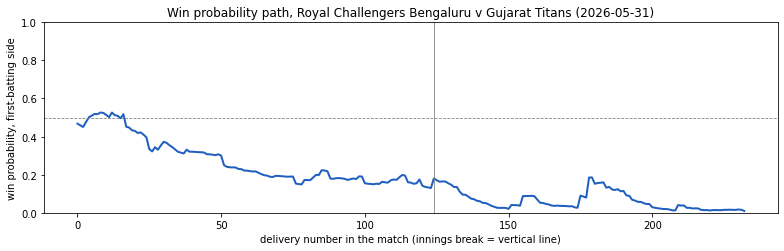

In [3]:
# ─────────────────────────────────────────────────────────────────────
# CELL 3 · DOES THE WIN PROBABILITY BEHAVE LIKE CRICKET? (start of innings, the innings break, and one real match)
# ─────────────────────────────────────────────────────────────────────
# 3a) At the very first ball of each innings, nobody should be a big favourite.
first = ball[(ball.innings_ball_num == 1) & ball.clean_match]
print("Win probability for the batting side at the very first ball:")
display(first.groupby("innings").wp_before.describe().round(3)[["count", "mean", "std", "min", "max"]])

# 3b) The two models must agree at the innings break: the first side's win probability on its LAST ball should be close to 1 minus
# the chasing side's probability on ITS first ball. A big gap would create a fake jump in "pressure" on that one ball.
last1 = ball[(ball.innings == 1) & ball.clean_match].groupby("match_id").tail(1).set_index("match_id").wp_before
first2 = ball[(ball.innings == 2) & (ball.innings_ball_num == 1) & ball.clean_match].set_index("match_id").wp_before
both = pd.concat([last1.rename("end_of_innings_1"), (1 - first2).rename("start_of_innings_2")], axis=1).dropna()
print(f"\nInnings break, {len(both)} matches: correlation {both.end_of_innings_1.corr(both.start_of_innings_2):.2f}, "
      f"average gap {(both.end_of_innings_1 - both.start_of_innings_2).abs().mean():.3f} (probability points).")
print("A gap of a few points is a limitation of having two models; it only touches the one ball that closes innings 1.")

# 3c) One real match, ball by ball: the 2026 IPL final (win probability of the side that batted first, with the over-by-over table).
fin = matches[(matches.tier == "IPL") & (matches.stage == "Final") & (matches.year == 2026)].iloc[0]
mb = ball[ball.match_id == fin.match_id].copy()
mb["wp_first_side"] = np.where(mb.innings == 1, mb.wp_before, 1 - mb.wp_before)         # always from the point of view of the first batting side
mb["step"] = np.arange(len(mb))
print(f"\nMatch: {fin.home_team} v {fin.away_team}, {fin.match_date}. Result: {fin.result}")
ov = mb.groupby(["innings", "over"]).agg(score_end=("score_before", "last"), wkts=("wkts_before", "last"), wp_first_side=("wp_first_side", "last")).round(3)
display(ov.T)
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(mb.step, mb.wp_first_side, lw=2, color="#1f5fbf"); ax.axhline(0.5, color="grey", lw=0.8, ls="--")
ax.axvline((mb.innings == 1).sum(), color="grey", lw=0.8); ax.set_ylim(0, 1)
ax.set_xlabel("delivery number in the match (innings break = vertical line)"); ax.set_ylabel("win probability, first-batting side")
ax.set_title(f"Win probability path, {fin.home_team} v {fin.away_team} ({fin.match_date})"); plt.tight_layout(); plt.show()

**Procedure**
1. Checked the win probability at the very first ball of each innings.
2. Compared the first side's probability on its last ball with 1 minus the chaser's probability on its first ball, to measure disagreement between the two models at the innings break.
3. Plotted one real match, the 2026 IPL final (RCB v GT, 31 May 2026), as the first-batting side's win probability ball by ball.

**Observations**
- First ball, innings 1: mean 0.500, std 0.076, range 0.21–0.79, so no side starts as a big favourite. First ball, innings 2: mean 0.499, std 0.237, range 0.001–0.972. The target alone decides how hard a chase is, which is why the spread is wide.
- Innings break: correlation 0.96 and an average gap of 0.06 probability points. This is the cost of having two models. It touches only the one ball that closes innings 1, and that ball is left out of leverage training.
- In the final, the first-batting side slid from about 0.5 to about 0.2 by the 12th–15th over as wickets fell, sat near 0.18 at the break, and faded to nearly 0 as RCB won by 5 wickets. The short bounce near delivery 178 matches a setback for the chasers. The path moves ball by ball in a cricket-like way.

In [4]:
# ─────────────────────────────────────────────────────────────────────
# CELL 4 · FROM WIN PROBABILITY TO THE LEVERAGE INDEX (LI)
# Purpose: measure how much a ball can swing the match BEFORE it is bowled, from the situation only.
# ─────────────────────────────────────────────────────────────────────
# 4a) THE SWING OF EACH BALL. For every delivery, win probability after the ball minus before it.
#   - not the last ball of an innings: after = the win probability at the next ball (same innings);
#   - last ball of innings 2: after = what actually happened (1 if the chasing side won, else 0);
#   - last ball of innings 1: left EMPTY. Its "after" would come from the other innings' model, and the small disagreement between the
#     two models at the innings break (cell 3) would show up as a fake spike of pressure on that one ball. We do not train on it;
#     its leverage is simply predicted from the neighbouring balls.
g = ball.groupby(["match_id", "innings"])
ball["wp_after"] = g.wp_before.shift(-1)
end2 = (ball.innings == 2) & ball.wp_after.isna()
ball.loc[end2, "wp_after"] = ball.loc[end2, "bat_won"].where(ball.loc[end2, "clean_match"])
ball["dwp"] = ball.wp_after - ball.wp_before
ok = ball.clean_match & ball.dwp.notna()
print(f"Balls with a measurable swing: {ok.sum():,}. Average |swing| per ball: {ball.loc[ok, 'dwp'].abs().mean():.4f}  (average signed swing: {ball.loc[ok, 'dwp'].mean():+.5f}, "
      "close to zero as it must be: a fair model has no built-in drift)")

# 4b) LEVERAGE INDEX = the EXPECTED size of the swing on the next ball, given only what is known before the ball.
# FUNCTIONAL: this is not "what happened" (a dot ball in a tense moment is still a tense moment). It is "how much COULD this ball
# change the result". TECHNICAL: if we learn the average of |swing| as a function of the situation, that average IS the expected
# swing. So we train a regression (LightGBM) with target |swing| on the situation, grouped by match, out-of-fold as always.
LI_FEATS = ["innings", "over", "legal_before", "balls_left", "score_before", "wkts_before", "wp_before", "crr_s", "target", "runs_needed", "rrr",
            "z", "score_vs_par", "elo_diff", "venue_par_effect"]
Xli = ball[LI_FEATS]; yli = ball.dwp.abs()
P = dict(objective="regression", learning_rate=0.03, num_leaves=15, min_child_samples=400, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
         reg_lambda=10.0, n_jobs=-1, random_state=SEED, verbosity=-1)
oof = pd.Series(np.nan, index=ball.index); best = []
for tr, te in folds:
    tr = tr[ok.to_numpy()[tr]]
    m_tr = np.unique(groups[tr]); m_val = rng.choice(m_tr, size=int(0.1 * len(m_tr)), replace=False); iv = np.isin(groups[tr], m_val)
    mdl = lgb.train(P, lgb.Dataset(Xli.iloc[tr[~iv]], yli.iloc[tr[~iv]]), 2000, valid_sets=[lgb.Dataset(Xli.iloc[tr[iv]], yli.iloc[tr[iv]])],
                    callbacks=[lgb.early_stopping(100, verbose=False)])
    oof.iloc[te] = mdl.predict(Xli.iloc[te], num_iteration=mdl.best_iteration); best.append(mdl.best_iteration)
ball["li_raw"] = oof.clip(lower=0)
print(f"Best trees per fold: {best}")
# NORMALISE so that the average ball has LI = 1.0 (the convention used in baseball, where "LI 2.0" means twice as tense as normal).
ball["li"] = ball.li_raw / ball.li_raw.mean()

# 4c) Does the predicted LI match the realised swings? (deciles of predicted LI vs the average |swing| that actually happened)
r = ok & ball.li.notna()
d = pd.DataFrame({"li": ball.loc[r, "li"], "real": ball.loc[r, "dwp"].abs()}); d["decile"] = pd.qcut(d.li, 10, labels=False) + 1
display(d.groupby("decile").agg(balls=("li", "size"), predicted_LI=("li", "mean"), avg_real_swing=("real", "mean")).round(4))
print(f"Correlation between predicted LI and the realised |swing| = {d.li.corr(d.real):.3f}; R-squared of the LI model = {1 - ((d.real - d.li * ball.loc[r, 'dwp'].abs().mean()) ** 2).sum() / ((d.real - d.real.mean()) ** 2).sum():.3f}")
print("(A modest R-squared is expected: the SIZE of a single ball's swing is mostly luck. What matters is that the average is right.)")

# 4d) Where is the pressure? Average LI by innings and over.
tab = ball.groupby(["innings", "over"]).li.mean().unstack(0).round(2).T
display(tab)

Balls with a measurable swing: 177,083. Average |swing| per ball: 0.0135  (average signed swing: +0.00001, close to zero as it must be: a fair model has no built-in drift)
Best trees per fold: [686, 1143, 1998, 842, 466]


,balls,predicted_LI,avg_real_swing
decile,,,
1,17709,0.1018,0.0015
2,17708,0.3784,0.0051
3,17708,0.5818,0.0082
4,17708,0.7120,0.0097
5,17709,0.7735,0.0106
6,17708,0.8723,0.0121
7,17708,1.0207,0.0141
8,17708,1.1378,0.0158
9,17708,1.4366,0.0199


Correlation between predicted LI and the realised |swing| = 0.479; R-squared of the LI model = 0.229
(A modest R-squared is expected: the SIZE of a single ball's swing is mostly luck. What matters is that the average is right.)


over,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
innings,,,,,,,,,,,,,,,,,,,,
1,0.9600,1.0700,1.1000,1.0800,1.0700,1.0000,0.6700,0.6800,0.6800,0.6800,0.6800,0.6700,0.6700,0.6600,0.6700,0.6700,0.6800,0.7200,0.8100,0.9600
2,1.0500,1.1300,1.1500,1.1500,1.1500,1.0900,0.9000,0.9100,0.9500,0.9800,1.0300,1.0900,1.1200,1.1000,1.2700,1.3400,1.4500,1.6100,1.9600,3.4400


**Procedure**
1. Computed each ball's swing: win probability after the ball minus before it. On the last ball of innings 2 the "after" is the actual result. On the last ball of innings 1 it is left empty, to avoid a fake spike from the innings-break model gap.
2. Defined the Leverage Index (LI) as the expected size of the swing, learned from the pre-ball situation only. A LightGBM model with target |swing| is trained out-of-fold, then scaled so that an average ball has LI = 1.0.
3. Checked LI against realised swings by decile and tabulated average LI by innings and over.

**Observations**
- 177,083 balls have a measurable swing. The average |swing| is 0.0137 and the signed average is +0.00001, so the win-probability model has no built-in drift.
- LI is well calibrated. The bottom decile has predicted LI 0.11 and a real swing of 0.0016, and the top decile has LI 2.89 and a real swing of 0.0386, about 2.8 times the average. The real swing rises steadily across all ten deciles.
- Correlation between predicted LI and realised |swing| is 0.48 (R² 0.23). A single ball's swing is mostly luck, but the average swing for a given situation is predicted correctly, which is what we need.
- Pressure by over: innings 1 sits at about 1.0–1.1 in the powerplay and drops to about 0.66–0.70 in the middle overs. Innings 2 starts at about 1.04 and climbs steadily to about 2.0 by over 19, because a live chase gets more decisive as balls run out.

In [5]:
# ─────────────────────────────────────────────────────────────────────
# CELL 5 · DEFINING A "PRESSURE BALL": thresholds on the Leverage Index, split by role, and a rules-based cross-check
# ─────────────────────────────────────────────────────────────────────
# 5a) THE THRESHOLD. A ball is a pressure ball when its LI is in the top q% of ALL balls. We compute 15%, 20%, 25% and 30% and use one
# as the MAIN definition; the final lists must survive the others (sensitivity). Because LI is normalised so that an average ball
# = 1.0, a threshold of 1.23 reads "at least 1.23 times as tense as an average ball".
QS = [0.15, 0.20, 0.25, 0.30]
PRIMARY_Q = 0.20          # <- the main definition. Change this one number to re-run everything with another threshold.
thr = {q: ball.li.quantile(1 - q) for q in QS}
for q in QS:
    ball[f"press_top{int(q*100)}"] = ball.li >= thr[q]
ball["press_main"] = ball[f"press_top{int(PRIMARY_Q*100)}"]

# WHY 20% AND NOT 25%: look at where the thresholds fall. In the first innings and the powerplay, LI sits on a flat plateau
# around 1.0 to 1.15, so a 25% cut-off (1.15) slices through that plateau and lets in many ordinary powerplay balls by a hair's breadth.
# At 20% (LI >= ~1.23) the set is made of balls that are clearly more tense than normal. The share of each innings and phase
# for every threshold is shown below so the choice is visible, not hidden.
bands = pd.cut(ball.over, [0, 6, 10, 15, 18, 20], labels=["overs 1-6", "7-10", "11-15", "16-18", "19-20"])
rows = []
for q in QS:
    f = ball[f"press_top{int(q*100)}"]
    rows.append({"share of balls": f"top {int(q*100)}%", "LI at least": thr[q], "from innings 2": (ball[f].innings == 2).mean(),
                 **{b: (bands[f] == b).mean() for b in bands.cat.categories}})
rows.append({"share of balls": "ALL balls", "LI at least": np.nan, "from innings 2": (ball.innings == 2).mean(), **{b: (bands == b).mean() for b in bands.cat.categories}})
display(pd.DataFrame(rows).set_index("share of balls").round(3))

# A baseball-style plain-language band for reports and the website: low < 0.85, medium 0.85-1.5, high > 1.5.
ball["li_band"] = pd.cut(ball.li, [-1, 0.85, 1.5, 1000], labels=["low", "medium", "high"]).astype(str)
print("\nLeverage bands (share of balls):", ball.li_band.value_counts(normalize=True).round(3).to_dict())

# 5b) PRESSURE IS DIFFERENT FOR THE BATTER AND THE BOWLER. Both need a tense ball, but the side that is comfortably ahead is not the one
# feeling it. So: BATTER pressure = pressure ball and the batting side's win probability is at most 60% (not cruising);
#                 BOWLER pressure = pressure ball and the batting side's win probability is at least 40% (the bowling side is not cruising).
# Balls where the game is on a knife-edge (40-60%) count for BOTH. One measure, two role-specific sets.
COMFORT = 0.60
for q in QS:
    k = int(q * 100); f = ball[f"press_top{k}"]
    ball[f"bat_press{k}"]  = f & (ball.wp_before <= COMFORT)
    ball[f"bowl_press{k}"] = f & (ball.wp_before >= 1 - COMFORT)
ball["bat_press"], ball["bowl_press"] = ball[f"bat_press{int(PRIMARY_Q*100)}"], ball[f"bowl_press{int(PRIMARY_Q*100)}"]
print(f"MAIN definition (top {int(PRIMARY_Q*100)}%): pressure {ball.press_main.mean():.1%} of balls | batter pressure {ball.bat_press.mean():.1%} | "
      f"bowler pressure {ball.bowl_press.mean():.1%} | both roles {(ball.bat_press & ball.bowl_press).mean():.1%}")

# 5c) RULES-BASED CROSS-CHECK. Three simple, model-free situations a coach would call tense, to see what the LI does and does not pick up:
#   R1: chasing in overs 16-20, required rate between 8 and 18, at most 8 wickets down (a tight finish);
#   R2: chasing in overs 7-15 with 5+ wickets down and a required rate of 8.5+ (a collapse under a steep rate);
#   R3: batting first in overs 17-20 with the score within 25 runs of par (the death, total still in the balance).
r1 = (ball.innings == 2) & (ball.over >= 16) & ball.rrr.between(8, 18) & (ball.wkts_before <= 8)
r2 = (ball.innings == 2) & ball.over.between(7, 15) & (ball.wkts_before >= 5) & (ball.rrr >= 8.5)
r3 = (ball.innings == 1) & (ball.over >= 17) & (ball.score_vs_par.abs() <= 25)
ball["rule_press"] = r1 | r2 | r3
out = pd.DataFrame({"rule": ["R1 tight finish in a chase", "R2 collapse under a steep rate", "R3 first-innings death, total in the balance"],
                    "share of balls": [r1.mean(), r2.mean(), r3.mean()], "average LI": [ball.li[r].mean() for r in (r1, r2, r3)],
                    "caught by main pressure set": [(r & ball.press_main).sum() / r.sum() for r in (r1, r2, r3)]}).set_index("rule")
display(out.round(3))
print("Reading. R1 is mostly caught by the LI (about 70%): the two definitions agree where cricket is most obviously tense. "
      "R2 (a collapse) has LOW leverage: with 5+ down and a steep rate the match is mostly lost, so one more ball hardly moves the result. "
      "That is the difference between PRESSURE AS LEVERAGE (the ball can decide the match) and strain (the player is struggling). "
      "R3 is low because a first-innings total can still be recovered or chased down. We take leverage as the definition and state this "
      "limit plainly in the report.")

,LI at least,from innings 2,overs 1-6,7-10,11-15,16-18,19-20
share of balls,,,,,,,
top 15%,1.4340,0.9910,0.3070,0.1730,0.2810,0.1530,0.0870
top 20%,1.2310,0.9460,0.3590,0.1800,0.2390,0.1250,0.0980
top 25%,1.1340,0.8340,0.4360,0.1620,0.2020,0.1040,0.0960
top 30%,1.0810,0.7300,0.5050,0.1420,0.1730,0.0890,0.0900
ALL balls,NaN,0.4740,0.3190,0.2080,0.2530,0.1420,0.0790



Leverage bands (share of balls): {'low': 0.532, 'medium': 0.332, 'high': 0.136}
MAIN definition (top 20%): pressure 20.0% of balls | batter pressure 12.8% | bowler pressure 13.5% | both roles 6.3%


,share of balls,average LI,caught by main pressure set
rule,,,
R1 tight finish in a chase,0.0390,2.9390,0.7070
R2 collapse under a steep rate,0.0350,0.5370,0.1330
"R3 first-innings death, total in the balance",0.0650,0.9080,0.0990


Reading. R1 is mostly caught by the LI (about 70%): the two definitions agree where cricket is most obviously tense. R2 (a collapse) has LOW leverage: with 5+ down and a steep rate the match is mostly lost, so one more ball hardly moves the result. That is the difference between PRESSURE AS LEVERAGE (the ball can decide the match) and strain (the player is struggling). R3 is low because a first-innings total can still be recovered or chased down. We take leverage as the definition and state this limit plainly in the report.


**Procedure**
1. Defined a pressure ball as one whose LI is in the top q% of all balls, for q = 15, 20, 25 and 30%. The main definition is the top 20% (change `PRIMARY_Q` to alter it). Showed where each threshold falls by innings and phase.
2. Created role-specific sets: batter pressure needs a pressure ball with the batting side's win probability at most 60%, and bowler pressure needs a pressure ball with the batting side's win probability at least 40%.
3. Cross-checked against three model-free rules a coach would call tense: a tight chase finish (R1), a collapse under a steep rate (R2), and first-innings death with the total in the balance (R3).

**Observations**
- LI thresholds are 1.43, 1.22, 1.15 and 1.09. The main set is 94% second-innings balls (99% at 15%, 71% at 30%). So pressure in this project mostly means a live chase.
- Phase mix of the main set: 36% overs 1–6, 18% overs 7–10, 24% overs 11–15, 13% overs 16–18 and 9% overs 19–20. A strict top 15% has fewer powerplay balls (30%) than a loose top 30% (52%), so the threshold matters, and the final lists must survive it.
- Main definition: 20.0% of balls are pressure, 12.8% are batter pressure, 13.6% are bowler pressure and 6.4% count for both. Leverage bands are 54% low, 33% medium and 13.5% high.
- Rule check: R1 (tight finish) is 4.0% of balls with average LI 2.94, and 71% are caught by the main set, so the two definitions agree where cricket is most obviously tense. R2 (collapse) has average LI 0.54 and only 13% caught, because with 5+ down and a steep rate the match is mostly decided. R3 (first-innings death) has average LI 0.89 and 8% caught. Leverage measures how much a ball can decide the match. It does not measure how much a player is struggling, and the report will say so. The death-overs measure planned for the Rajasthan Royals diagnosis covers the part that R3 shows leverage misses.

In [6]:
# ─────────────────────────────────────────────────────────────────────
# CELL 6 · DOES "PRESSURE" BEHAVE LIKE PRESSURE? Validation of the pressure sets
# ─────────────────────────────────────────────────────────────────────
# 6a) Cricket should look different in pressure balls: fewer boundaries and more wickets are not guaranteed, but the numbers tell
# us what the typical player does when the game is on the line. "Gap" = actual minus what the situation-only engine of notebook 04 expected.
# A negative batter gap means batters, on average, score less than the situation alone predicts when it is tense.
def behaviour(mask, label):
    d = ball[mask]; f = d[d.faced]
    return pd.Series({"balls": len(d), "runs per ball": d.total_runs.mean(), "dot-ball share": (d.total_runs == 0).mean(),
                      "boundary share": (d.is_four | d.is_six).mean(), "wicket rate": d.is_wicket_clean.mean(),
                      "batter gap (runs/ball)": (f.y_bat_runs - f.exp_bat_runs).mean(), "bowler gap (runs saved/ball)": (d.exp_runs_conc - d.y_runs_conc).mean()}, name=label)
tab = pd.concat([behaviour(ball.press_main, "pressure (main set)"), behaviour(~ball.press_main, "not pressure"),
                 behaviour(ball.bat_press, "batter pressure"), behaviour(ball.bowl_press, "bowler pressure"),
                 behaviour(ball.press_main & (ball.innings == 1), "pressure, innings 1"), behaviour(ball.press_main & (ball.innings == 2), "pressure, innings 2")], axis=1).T
display(tab.round(4))
n = ball.press_main.sum()
f = ball[ball.press_main & ball.faced]; se = (f.y_bat_runs - f.exp_bat_runs).std() / np.sqrt(len(f))
print(f"Typical batter gap in pressure balls: {(f.y_bat_runs - f.exp_bat_runs).mean():+.4f} runs/ball (+/- {2*se:.4f}). "
      "A value near zero means the engine already accounts for the tension: pressure then shows up as WHO beats or misses the engine, which is what we rate.")

# 6b) INDEPENDENCE FROM STAKES. The Leverage Index (how much THIS ball matters inside the match) and match stakes (how much THIS match
# matters for the season) are separate ideas. If they were strongly linked we would be double counting.
st = ball[ball.stakes_tier != "not measured"].groupby("stakes_tier").li.agg(["size", "mean"]).rename(columns={"size": "balls", "mean": "average LI"})
display(st.round(3))
print("Similar average LI across stakes tiers is the point: a final is not tense ball by ball just because it is a final; the stakes multiplier "
      "is applied separately in notebook 05c.")

# 6c) THE MOST TENSE BALLS. A cricketer should recognise these.
top = ball.sort_values("li", ascending=False).head(12)[["match_id", "innings", "over", "score_before", "wkts_before", "runs_needed", "balls_left", "wp_before", "li"]]
top["match"] = top.match_id.map(matches.set_index("match_id").apply(lambda r: f"{r.home_team} v {r.away_team} ({r.match_date})", axis=1))
display(top.drop(columns="match_id").set_index("match").round(2))

# 6d) HOW MANY PRESSURE BALLS WILL PLAYERS HAVE? This decides the minimum sample for the ratings (an open decision). For each
# threshold we count batters / bowlers with at least 40, 60 and 100 pressure balls in their role.
rows = []
for q in QS:
    k = int(q * 100)
    bp = ball[f"bat_press{k}"] & ball.faced; wp_ = ball[f"bowl_press{k}"]
    cb, cw = ball[bp].groupby("striker_id").size(), ball[wp_].groupby("bowler_id").size()
    rows.append({"threshold (top share)": f"{int(q*100)}%", **{f"batters >= {k}": (cb >= k).sum() for k in (40, 60, 100)}, **{f"bowlers >= {k}": (cw >= k).sum() for k in (40, 60, 100)}})
display(pd.DataFrame(rows).set_index("threshold (top share)"))
print("Reading: a wider definition gives more players enough balls to be rated fairly; a stricter one is purer but thinner. "
      "We rate on the main definition and check that the top-10 lists survive the other thresholds.")

,balls,runs per ball,dot-ball share,boundary share,wicket rate,batter gap (runs/ball),bowler gap (runs saved/ball)
pressure (main set),"40,193.0000",1.4659,0.3277,0.1905,0.0606,0.0037,-0.0011
not pressure,"160,768.0000",1.4013,0.3411,0.1769,0.0525,-0.0020,0.0047
batter pressure,"25,724.0000",1.4722,0.3295,0.1916,0.0642,0.0021,0.0008
bowler pressure,"27,034.0000",1.4444,0.3317,0.1877,0.0556,-0.0000,0.0020
"pressure, innings 1","2,190.0000",1.7416,0.3110,0.2466,0.1037,0.0600,-0.0496
"pressure, innings 2","38,003.0000",1.4500,0.3286,0.1872,0.0582,0.0005,0.0017


Typical batter gap in pressure balls: +0.0037 runs/ball (+/- 0.0178). A value near zero means the engine already accounts for the tension: pressure then shows up as WHO beats or misses the engine, which is what we rate.


,balls,average LI
stakes_tier,,
high (0.10-0.25),13865,1.0720
low (<0.05),13685,1.0310
medium (0.05-0.10),55212,1.0610
sudden-death / title (0.25+),7567,1.0230


Similar average LI across stakes tiers is the point: a final is not tense ball by ball just because it is a final; the stakes multiplier is applied separately in notebook 05c.


,innings,over,score_before,wkts_before,runs_needed,balls_left,wp_before,li
match,,,,,,,,
United Arab Emirates v Bangladesh (2025-05-19),2,20,204,8,2.0000,2,0.1700,26.4700
Kolkata Knight Riders v Lucknow Super Giants (2026-04-09),2,20,181,7,1.0000,1,0.4600,25.4200
Delhi Capitals v Gujarat Titans (2026-04-08),2,20,209,7,2.0000,2,0.5300,25.2900
Punjab Kings v Rajasthan Royals (2024-04-13),2,20,146,7,2.0000,2,0.5400,24.8400
Delhi Capitals v Gujarat Titans (2026-04-08),2,20,209,7,2.0000,1,0.3700,24.7100
Gujarat Titans v Chennai Super Kings (2022-04-17),2,20,168,7,2.0000,2,0.5200,24.6800
United Arab Emirates v Bangladesh (2025-05-19),2,20,203,8,3.0000,2,0.1300,23.7700
West Indies v Pakistan (2025-08-02),2,20,131,8,3.0000,1,0.0800,22.2100
Gujarat Titans v Sunrisers Hyderabad (2022-04-27),2,20,193,5,3.0000,1,0.7400,20.9700


,batters >= 40,batters >= 60,batters >= 100,bowlers >= 40,bowlers >= 60,bowlers >= 100
threshold (top share),,,,,,
15%,140,100,51,153,113,67
20%,169,130,78,190,139,91
25%,198,152,103,216,166,106
30%,214,169,122,236,188,129


Reading: a wider definition gives more players enough balls to be rated fairly; a stricter one is purer but thinner. We rate on the main definition and check that the top-10 lists survive the other thresholds.


**Procedure**
1. Compared behaviour in pressure and non-pressure balls (runs per ball, dot share, boundary share, wicket rate, and the batter and bowler gaps against the notebook-04 engine).
2. Checked that LI is separate from match stakes, by comparing average LI across stakes tiers.
3. Listed the 12 most tense balls and counted how many batters and bowlers reach 40, 60 and 100 pressure balls under each threshold.

**Observations**
- The typical batter gap in pressure balls is +0.0045 runs per ball (±0.018), which is statistically zero. The engine already accounts for tension, so pressure shows up as who beats or misses the engine, which is what we rate.
- Average LI is 1.02–1.10 across stakes tiers (title/sudden-death 1.02, high 1.10, medium 1.06, low 1.04), so tense balls are not simply those from important matches. Leverage and stakes are separate ideas, and the stakes multiplier will be applied in notebook 05c.
- The 12 most tense balls are all innings-2, over-20 deliveries with 1–5 runs needed off 1–2 balls (LI 20.4–21.7), from IPL, internationals and A-team matches. A cricketer would recognise them. For some of them the predicted win probability is only 0.11–0.45, even with 1 run needed off 1 ball. That looks low and gets a calibration check in 05c. It does not change the ranking.
- Sample sizes at the main 20% definition: 132 batters and 142 bowlers have 60+ pressure balls, and 77 batters and 89 bowlers have 100+. At 25%: 147 and 168. At 15%: 104 and 114. A minimum of 60 pressure balls gives a workable pool at every threshold.

In [7]:
# ─────────────────────────────────────────────────────────────────────
# CELL 7 · SAVE (ball table, win-probability models for the website, leverage engine)
# ─────────────────────────────────────────────────────────────────────
import json
# 7a) Final models trained on ALL clean matches, so the website can compute win probability for any "what if" situation.
# (The ratings themselves use the out-of-fold numbers above, never these.) A logistic regression is just a list of numbers,
# so it is stored as plain JSON: for each input, its average and spread (to standardise) and its weight, plus an intercept.
MODEL_DIR = OUT_DIR / "models"; MODEL_DIR.mkdir(exist_ok=True)
export = {}
for inn in [1, 2]:
    r = ((ball.innings == inn) & ball.clean_match).to_numpy(); X = ball.loc[r, FEATS[inn]].fillna(0); y = ball.loc[r, "bat_won"]
    mu, sd = X.mean(), X.std().replace(0, 1)
    lr = LogisticRegression(max_iter=3000).fit((X - mu) / sd, y)
    export[f"innings_{inn}"] = {"features": FEATS[inn], "mean": mu.tolist(), "sd": sd.tolist(), "coef": lr.coef_[0].tolist(), "intercept": float(lr.intercept_[0])}
export["spread_per_sqrt_ball"] = SPREAD
mdl_rem = lgb.train(dict(objective="regression", learning_rate=0.05, num_leaves=15, min_child_samples=400, reg_lambda=10, n_jobs=-1, random_state=SEED,
                         verbosity=-1, monotone_constraints=[1, -1, 1]), lgb.Dataset(ball[ok_rem][REM_F], ball[ok_rem].rem_actual), 300)
mdl_rem.save_model(str(MODEL_DIR / "e_rem.txt"))
(MODEL_DIR / "win_probability.json").write_text(json.dumps(export, indent=1))
print("Saved win-probability models:", sorted(export), "and the E_rem engine in", MODEL_DIR)

# 7b) Final leverage engine (trained on all balls with a measurable swing), for scoring any situation on the website.
okm = (ball.clean_match & ball.dwp.notna()).to_numpy()
mdl_li = lgb.train(dict(objective="regression", learning_rate=0.03, num_leaves=15, min_child_samples=400, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                        reg_lambda=10.0, n_jobs=-1, random_state=SEED, verbosity=-1), lgb.Dataset(ball.loc[okm, LI_FEATS], ball.loc[okm, "dwp"].abs()), int(np.mean(best) * 1.1))
mdl_li.save_model(str(MODEL_DIR / "leverage.txt"))
(MODEL_DIR / "leverage_meta.json").write_text(json.dumps({"features": LI_FEATS, "mean_raw_li": float(ball.li_raw.mean()), "thresholds": {str(q): float(v) for q, v in thr.items()}}, indent=1))

# 7c) Save the ball table. Temporary helper columns are dropped to keep the file lean.
ball = ball.drop(columns=["wk_rrr", "wk_bl", "rrr_sq", "bl_sq", "svp_bl", "svp_wk", "z_sq", "z_bl", "z_wk", "rem_actual"], errors="ignore")
print("Columns added by this notebook:", [c for c in ball.columns if c in new_cols + ["e_rem", "z", "crr_s", "bat_won", "clean_match"]])
print("Saved ball_master:", ball.shape, save_table(ball, "ball_master"))

Saved win-probability models: ['innings_1', 'innings_2', 'spread_per_sqrt_ball'] and the E_rem engine in interim\models
Columns added by this notebook: ['bat_won', 'clean_match', 'e_rem', 'z', 'crr_s', 'wp_before', 'wp_after', 'dwp', 'li_raw', 'li', 'press_top15', 'press_top20', 'press_top25', 'press_top30', 'press_main', 'li_band', 'bat_press15', 'bowl_press15', 'bat_press20', 'bowl_press20', 'bat_press25', 'bowl_press25', 'bat_press30', 'bowl_press30', 'bat_press', 'bowl_press', 'rule_press']
Saved ball_master: (200961, 141) parquet


**Procedure**
1. Refit the two logistic win-probability models on all clean matches and saved them as plain JSON (means, spreads, weights and intercept) so the website can score any "what if" situation. Also saved the E_rem engine.
2. Refit the leverage model on all measurable balls and saved it with its metadata (features, mean raw LI and thresholds).
3. Dropped temporary helper columns and saved the ball table.

**Observations**
- Saved `win_probability.json`, `e_rem.txt`, `leverage.txt` and `leverage_meta.json` in `interim/models`.
- `ball_master` now has 200,961 rows and 141 columns. The new columns include wp_before, wp_after, dwp, li, li_band, press_main, the four threshold sets, and the role-specific batter and bowler pressure columns.
- Ratings use the out-of-fold numbers only. The refit models exist for the website.